В цьому ноутбуці наглядно демонструєтся робота бектест алгоритму на всій доступній історії аткиву

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
STOCK = 'ETH'

# stocks

In [4]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,XRP,BNB,ADA,SOL,DOGE,DOT,LTC,LINK,...,XVG,BCN,NXT,PPC,NMC,DGB,SC,QTUM,ICX,LSK
Date,,,,,,,,,,,,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.058550,NaN,...,NaN,NaN,NaN,1.540270,1.264560,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.685230,NaN,...,NaN,NaN,NaN,1.685280,1.229760,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.327770,NaN,...,NaN,NaN,NaN,1.216330,1.104190,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.286440,NaN,...,NaN,NaN,NaN,1.641050,1.194410,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.245920,NaN,...,NaN,NaN,NaN,1.488790,1.110980,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,1.334452,740.823608,0.223782,106.422340,0.081809,1.149771,61.531612,12.320927,...,0.002583,0.000059,NaN,0.446449,1.317299,0.003360,0.000820,0.877745,0.009176,0.197685
2026-10-21,84011.968750,2470.766113,1.363619,745.868347,0.224979,106.793655,0.081867,1.141323,61.454342,12.484719,...,0.002605,0.000037,NaN,0.343409,1.176803,0.003399,0.000850,0.889200,0.008703,0.196787
2026-10-22,81311.890625,2386.189209,1.307656,730.476624,0.212025,103.542320,0.078676,1.111869,58.756485,11.943166,...,0.002455,0.000029,NaN,0.342047,1.535211,0.003527,0.000893,0.852186,0.009433,0.183983


In [5]:
prices = df_stocks[STOCK].dropna()

In [6]:
strategy = {
    "buy_amount": 10,
}

22:42:08 - cmdstanpy - INFO - Chain [1] start processing
22:42:09 - cmdstanpy - INFO - Chain [1] done processing


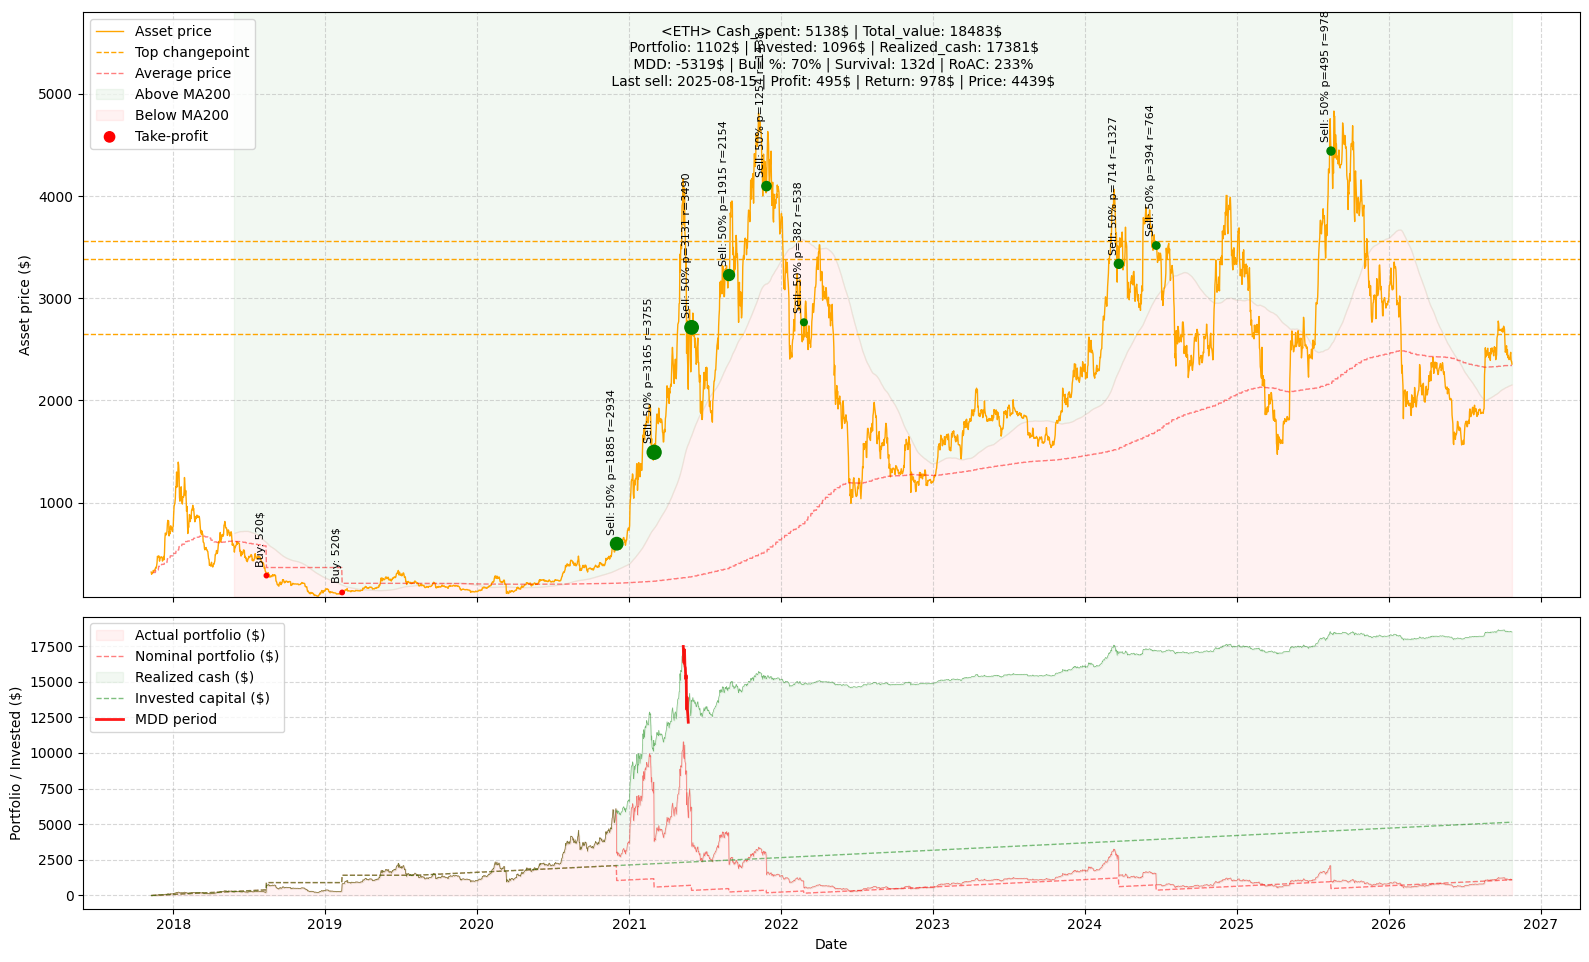

In [7]:
bt = BacktestDCA(
target=STOCK,
prices=prices,
strategy=strategy
)
result, metrics = bt.run()
ploter(metrics=metrics, history=result)

In [8]:
metrics

{'Target': 'ETH',
 'Cash_spent': 5138,
 'Realized_cash': 17381,
 'Portfolio': 1102,
 'Invested': 1096,
 'Total_value': 18483,
 'Bull_history': 70,
 'MDD': -5319,
 'Survival': 132.42857142857142,
 'RoAC': 233}

In [9]:
result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2017-11-09,320.884003,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-10,299.252991,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-11,314.681000,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-12,307.907990,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-11-13,316.716003,0.031258,9.900000,9.9,0.0,0.0,0.000000,,9.900000,316.716003,9.900000
...,...,...,...,...,...,...,...,...,...,...,...
2026-10-20,2446.730713,0.468031,1096.154297,5138.1,0.0,0.0,17381.133529,,1145.146968,2342.052557,18526.280497
2026-10-21,2470.766113,0.468031,1096.154297,5138.1,0.0,0.0,17381.133529,,1156.396291,2342.052557,18537.529821
2026-10-22,2386.189209,0.468031,1096.154297,5138.1,0.0,0.0,17381.133529,,1116.811639,2342.052557,18497.945168
